# 04. Visualizaciones Integradas, Simulador de Escenarios y Demostración End-to-End en Notebook
**Universidad EAFIT — SI3003 Inteligencia Artificial (2026-1)**  
**Proyecto Final Integrador:** Sistema Inteligente de Vigilancia y Asistencia para la Calidad del Aire en el Valle de Aburrá (SIATA – AMVA)

---

## Propósito de este Cuaderno Integrador
Además de la aplicación interactiva en Streamlit (`streamlit run app.py`), este cuaderno ejecuta e ilustra de punta a punta todos los componentes visuales y conversacionales del sistema directamente en formato Notebook:
1. **Comparación Geoespacial Semafórica del Valle de Aburrá:** Día de episodio crítico POECA (`2024-03-01`) vs Día de ventilación limpia (`2025-07-15`).
2. **Panel Temporal Multiestación con Umbrales Normativos POECA (`12`, `37` y `55.5 µg/m³`).**
3. **Matriz de Simulación Climática What-If (Parte 1):** Respuesta probabilística de las 5 estaciones ante escenarios contrastantes (Calma + Alta Humedad vs Vientos Alisios + Lluvia Nocturna).
4. **Sesión Conversacional Multi-Turno con el Agente Inteligente (Parte 2).**


In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import COLOR_MAP_HEX, get_station_summary, load_air_quality_data
from src.classical_model import predict_station_air_quality
from src.agent_core import AirQualityAgent

plt.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", font_scale=1.0)

df = load_air_quality_data()


## 1. Mapa Comparativo de Estaciones: Episodio Crítico POECA vs Atmósfera Limpia

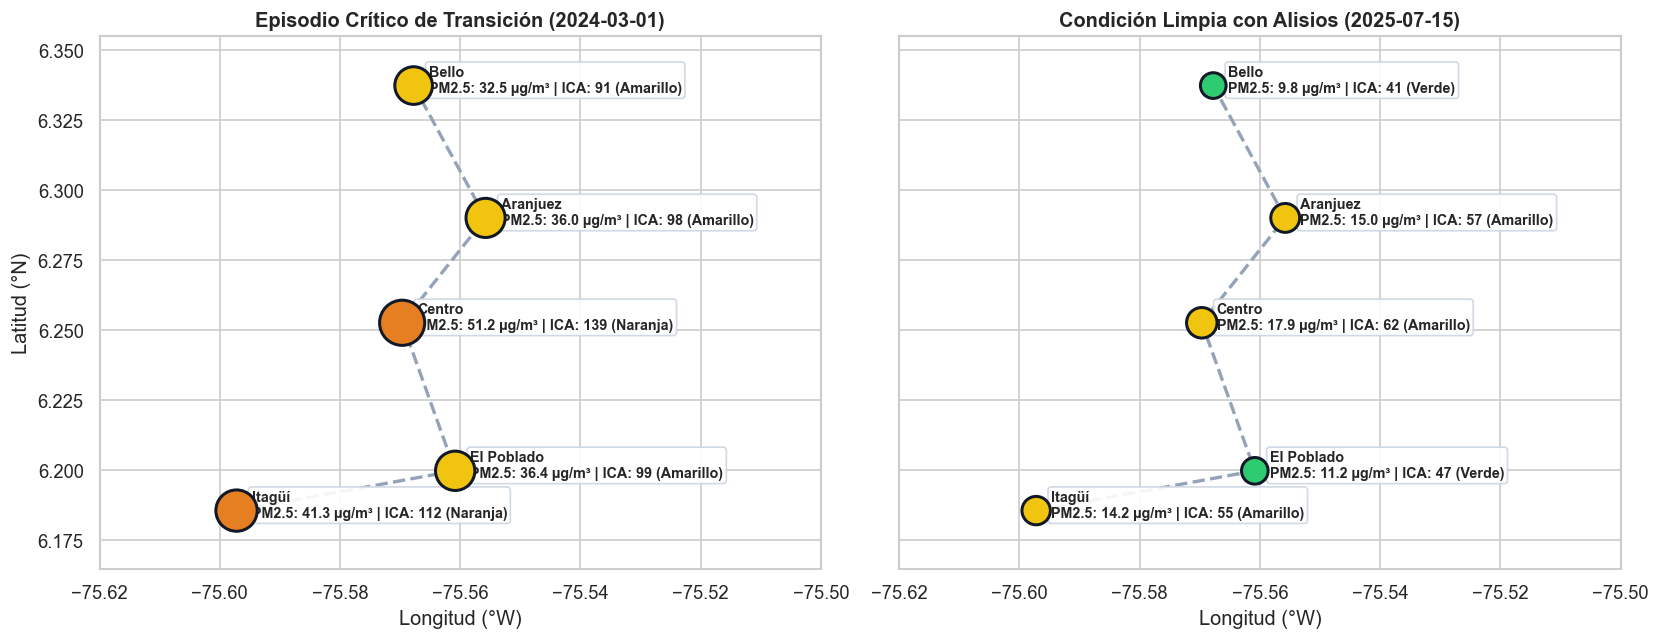

Resumen Tabular del Episodio Crítico (2024-03-01):


,estacion,municipio,pm25,ica,categoria_ica,color_ica,velocidad_viento,humedad_relativa
0,Centro,Medellín,51.22,138.8,Dañina a Grupos Sensibles,Naranja,0.69,71.10
1,Itagüí,Itagüí,41.29,112.2,Dañina a Grupos Sensibles,Naranja,0.99,52.11
2,El Poblado,Medellín,36.43,98.8,Aceptable,Amarillo,0.61,73.51
3,Aranjuez,Medellín,36.01,98.0,Aceptable,Amarillo,3.94,66.78
4,Bello,Bello,32.54,91.1,Aceptable,Amarillo,2.18,56.14


In [2]:
snap_crit = get_station_summary(df, fecha="2024-03-01")
snap_clean = get_station_summary(df, fecha="2025-07-15")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)

for ax, snap, title in [
    (axes[0], snap_crit, "Episodio Crítico de Transición (2024-03-01)"),
    (axes[1], snap_clean, "Condición Limpia con Alisios (2025-07-15)"),
]:
    # Trazar eje esquemático del Río Medellín / Aburrá de Sur a Norte
    ordered = snap.sort_values("latitud")
    ax.plot(ordered["longitud"], ordered["latitud"], color="#94a3b8", linestyle="--", linewidth=2.0, zorder=1, label="Eje Cuenca Río Aburrá")
    ax.scatter(
        snap["longitud"],
        snap["latitud"],
        s=snap["pm25"] * 12 + 120,
        c=snap["hex_color"],
        edgecolors="#111827",
        linewidth=1.8,
        zorder=4,
    )
    for _, r in snap.iterrows():
        ax.annotate(
            f"{r['estacion']}\nPM2.5: {r['pm25']:.1f} µg/m³ | ICA: {r['ica']:.0f} ({r['color_ica']})",
            (r["longitud"], r["latitud"]),
            xytext=(9, -4),
            textcoords="offset points",
            fontsize=8.6,
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.22", fc="white", ec="#cbd5e1", alpha=0.9),
        )
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Longitud (°W)")
    ax.set_xlim(-75.62, -75.50)
    ax.set_ylim(6.165, 6.355)

axes[0].set_ylabel("Latitud (°N)")
plt.tight_layout()
plt.show()

print("Resumen Tabular del Episodio Crítico (2024-03-01):")
display(snap_crit[["estacion", "municipio", "pm25", "ica", "categoria_ica", "color_ica", "velocidad_viento", "humedad_relativa"]])


## 2. Evolución Temporal Comparada (Centro vs Itagüí vs El Poblado) con Umbrales POECA

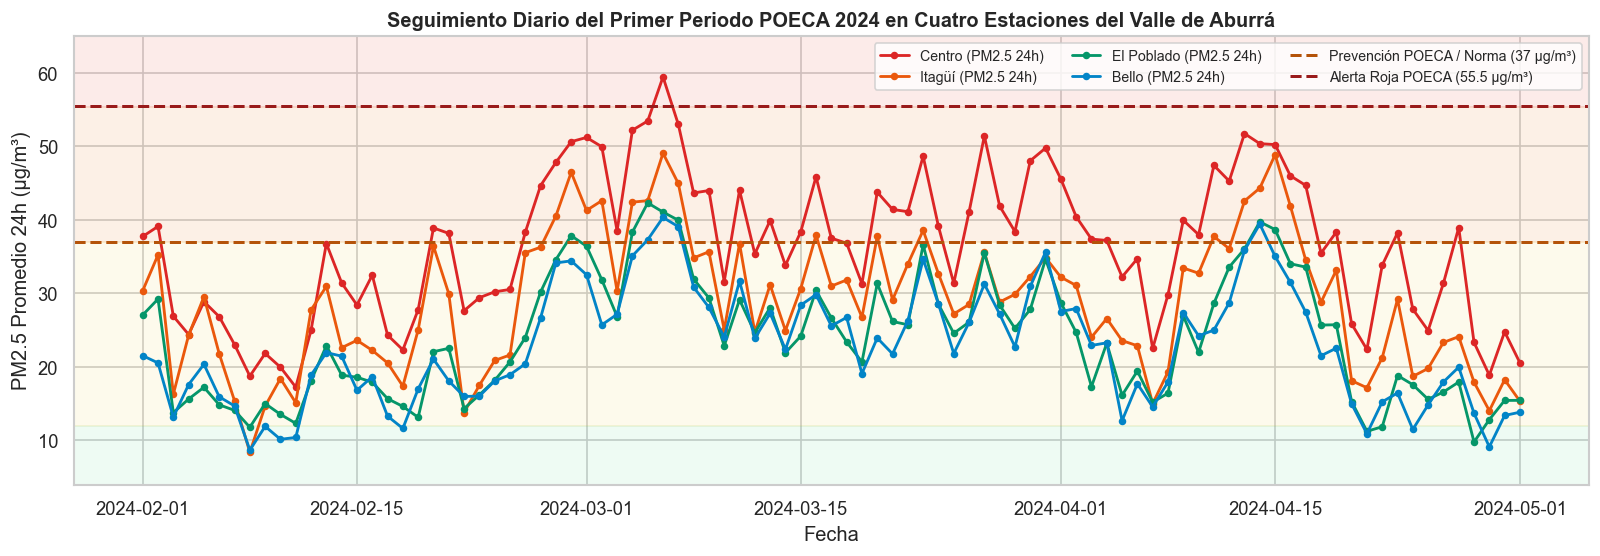

In [3]:
sub_q1 = df[(df["fecha"] >= "2024-02-01") & (df["fecha"] <= "2024-05-01")].copy()
sub_q1["fecha_dt"] = pd.to_datetime(sub_q1["fecha"])

fig, ax = plt.subplots(figsize=(13.5, 4.8))
ax.axhspan(0, 12.0, color="#2ecc71", alpha=0.08)
ax.axhspan(12.0, 37.0, color="#f1c40f", alpha=0.08)
ax.axhspan(37.0, 55.4, color="#e67e22", alpha=0.11)
ax.axhspan(55.4, 70.0, color="#e74c3c", alpha=0.11)

for st_name, col in [("Centro", "#dc2626"), ("Itagüí", "#ea580c"), ("El Poblado", "#059669"), ("Bello", "#0284c7")]:
    s = sub_q1[sub_q1["estacion"] == st_name].sort_values("fecha_dt")
    ax.plot(s["fecha_dt"], s["pm25"], marker="o", markersize=3.5, linewidth=1.7, color=col, label=f"{st_name} (PM2.5 24h)")

ax.axhline(37.0, color="#b45309", linestyle="--", linewidth=1.8, label="Prevención POECA / Norma (37 µg/m³)")
ax.axhline(55.5, color="#991b1b", linestyle="--", linewidth=1.8, label="Alerta Roja POECA (55.5 µg/m³)")
ax.set_ylim(4, 65)
ax.set_title("Seguimiento Diario del Primer Periodo POECA 2024 en Cuatro Estaciones del Valle de Aburrá", fontweight="bold")
ax.set_ylabel("PM2.5 Promedio 24h (µg/m³)")
ax.set_xlabel("Fecha")
ax.legend(ncol=3, loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.show()


## 3. Simulador Matricial de Escenarios Meteorológicos (Modelo Propio Gaussian HMM)
Evaluamos para las **5 estaciones** cómo cambian las predicciones y probabilidades posteriores del modelo propio bajo tres escenarios meteorológicos representativos.


In [4]:
scenarios = [
    ("Escenario A: Ventilación Óptima + Lluvia", 2.8, 52.0, 14.0, 18.0),
    ("Escenario B: Transición Moderada", 1.2, 68.0, 29.0, 0.0),
    ("Escenario C: Calma + Inversión Térmica Severa", 0.4, 86.0, 44.0, 0.0),
]

sim_rows = []
for sc_name, w, h, pm_prev, rain in scenarios:
    for st_name in ["Bello", "Aranjuez", "Centro", "El Poblado", "Itagüí"]:
        pred = predict_station_air_quality(
            estacion=st_name, viento=w, humedad=h, pm25_previo=pm_prev, precipitacion=rain
        )
        probs = pred["probabilidades_por_estado"]
        sim_rows.append(
            {
                "Escenario": sc_name,
                "Estación": st_name,
                "PM2.5 Est. (µg/m³)": pred["pm25_estimado_ugm3"],
                "Color Predicho": pred["color_ica_predicho"],
                "Nivel POECA": pred["nivel_poeca_asociado"],
                "P(Verde)": probs["Buena (Verde)"],
                "P(Amarillo)": probs["Aceptable (Amarillo)"],
                "P(Naranja)": probs["Dañina a Grupos Sensibles (Naranja)"],
                "P(Rojo)": probs["Dañina a la Salud (Rojo)"],
            }
        )

df_sim = pd.DataFrame(sim_rows)
display(df_sim)


,Escenario,Estación,PM2.5 Est. (µg/m³),Color Predicho,Nivel POECA,P(Verde),P(Amarillo),P(Naranja),P(Rojo)
0,Escenario A: Ventilación Óptima + Lluvia,Bello,2.0,Amarillo,Nivel Normal (Seguimiento Preventivo),0.4654,0.5340,0.0004,0.0002
1,Escenario A: Ventilación Óptima + Lluvia,Aranjuez,6.6,Amarillo,Nivel Normal (Seguimiento Preventivo),0.2624,0.7358,0.0015,0.0002
2,Escenario A: Ventilación Óptima + Lluvia,Centro,2.0,Amarillo,Nivel Normal (Seguimiento Preventivo),0.0970,0.9017,0.0010,0.0003
3,Escenario A: Ventilación Óptima + Lluvia,El Poblado,2.0,Amarillo,Nivel Normal (Seguimiento Preventivo),0.4212,0.5782,0.0004,0.0002
4,Escenario A: Ventilación Óptima + Lluvia,Itagüí,2.0,Amarillo,Nivel Normal (Seguimiento Preventivo),0.2348,0.7642,0.0007,0.0003
5,Escenario B: Transición Moderada,Bello,28.4,Amarillo,Nivel Normal (Seguimiento Preventivo),0.0152,0.9095,0.0745,0.0008
6,Escenario B: Transición Moderada,Aranjuez,33.7,Amarillo,Nivel Normal (Seguimiento Preventivo),0.0030,0.8203,0.1760,0.0008
7,Escenario B: Transición Moderada,Centro,28.1,Amarillo,Nivel Normal (Seguimiento Preventivo),0.0016,0.9187,0.0793,0.0004
8,Escenario B: Transición Moderada,El Poblado,26.3,Amarillo,Nivel Normal (Seguimiento Preventivo),0.0171,0.9359,0.0464,0.0007
9,Escenario B: Transición Moderada,Itagüí,28.1,Amarillo,Nivel Normal (Seguimiento Preventivo),0.0049,0.9171,0.0774,0.0006


## 4. Demostración Conversacional Completa con el Agente Inteligente
Ejecutamos tres turnos representativos de usuario ciudadano y tomador de decisiones ambiental, renderizando las respuestas completas en Markdown enriquecido junto con el conteo de pasos y citas verificadas.


In [5]:
agent = AirQualityAgent(t_max=6)

demo_questions = [
    "Soy deportista asmático y vivo cerca de Itagüí. Consulta cómo estuvo Itagüí el 2024-03-22 y dime si podía salir a trotar y qué mascarilla usar.",
    "Pronostica qué pasará mañana en el Centro si el viento baja a 0.4 m/s con 85% de humedad y PM2.5 previo de 52 ug/m3, e indica qué medidas exige el POECA.",
]

for idx, q in enumerate(demo_questions, start=1):
    resp = agent.ask(q)
    display(Markdown(f"---\n### 🗣️ Turno {idx} — Consulta del Usuario\n> *{q}*"))
    display(
        Markdown(
            f"**🔍 Auditoría del Loop:** `Pasos = {resp.total_steps}/6` | "
            f"`Tools = {resp.tools_called}` | `Citas = {len(resp.citations)}` | "
            f"`Backend = {resp.backend_used}`\n\n" + resp.answer
        )
    )


---
### 🗣️ Turno 1 — Consulta del Usuario
> *Soy deportista asmático y vivo cerca de Itagüí. Consulta cómo estuvo Itagüí el 2024-03-22 y dime si podía salir a trotar y qué mascarilla usar.*

**🔍 Auditoría del Loop:** `Pasos = 3/6` | `Tools = ['get_air_quality_data', 'search_poeca_protocols']` | `Citas = 4` | `Backend = local-hybrid:Qwen2.5-0.5B-Instruct+ReAct`

### 📍 Estado Observado — Estación Itagüí (2024-03-22)
- **Estación oficial:** Itagüí (Casa de Justicia - Corredor Sur Industrial) (*Representatividad Poblacional / Industrial-Urbana*)
- **Concentración $PM_{2.5}$ (24h):** **`34.0 µg/m³`** (máximo horario `62.0 µg/m³`, media móvil 7 días `32.62 µg/m³`), valor que **cumple el límite máximo diario nacional de `37.0 µg/m³`**.
- **Índice ICA:** **`94.1`** — Categoría **Aceptable** (Color **Amarillo**).
- **Condiciones meteorológicas asociadas:** Viento `0.36 m/s`, Humedad relativa `53.22%`, Temperatura `25.33 °C`, Precipitación `0.0 mm` (*Gestión Episodios (POECA)*).
- [Fuente: Datos Abiertos IDEAM-SISAIRE / Red SIATA-AMVA (Recurso g4t8-zkc3), Estación Itagüí (Casa de Justicia - Corredor Sur Industrial), Fecha 2024-03-22]

### 📜 Marco Normativo POECA y Recomendaciones Técnicas

**1. Dinámica Atmosférica, Meteorología y Red de Monitoreo del Valle de Aburrá — Sección 3. Inventario de Emisiones y Estaciones Representativas del Estudio — Estaciones Clave Analizadas en el Sistema Integrado (SISAIRE / SIATA)**
1. **Centro (`TRÁFICO CENTRO` — Medellín, ID SISAIRE 29509, Lat 6.2527, Lon -75.5697):** Estación de **Tráfico Urbano** en el corazón de La Candelaria (cerca del Museo de Antioquia). Registra las concentraciones más elevadas por exposición directa a rutas de buses y flujo vehicular intenso; referencia clave para la ZUAP Centro.
2. **El Poblado (`I.E. JOSÉ FÉLIX` — Medellín Sur, ID SISAIRE 31373, Lat 6.1999, Lon -75.5608):** Estación de **Representatividad Poblacional (Fondo Urbano Residencial)** en la comuna 14...
[Fuente: Dinámica Atmosférica, Meteorología y Red de Monitoreo del Valle de Aburrá (SIATA-METEO-RED-2025), Sección 3. Inventario de Emisiones y Estaciones Representativas del Estudio — Estaciones Clave Analizadas en el Sistema Integrado (SISAIRE / SIATA)]

**2. Dinámica Atmosférica, Meteorología y Red de Monitoreo del Valle de Aburrá — Disposiciones Generales**
**Fuente Técnica:** Documentación Científica SIATA — Área Metropolitana del Valle de Aburrá (AMVA) y Subsistema SISAIRE (IDEAM)
[Fuente: Dinámica Atmosférica, Meteorología y Red de Monitoreo del Valle de Aburrá (SIATA-METEO-RED-2025), Disposiciones Generales]

**3. Dinámica Atmosférica, Meteorología y Red de Monitoreo del Valle de Aburrá — Sección 3. Inventario de Emisiones y Estaciones Representativas del Estudio**
De acuerdo con el Inventario de Emisiones Atmosféricas del AMVA (actualización Universidad Pontificia Bolivariana / AMVA):
- **Fuentes Móviles (~79% – 81% del $PM_{2.5}$ primario):** Transporte de carga pesada y volquetas (~42%–50%), motocicletas de 2 y 4 tiempos, buses y automóviles particulares.
- **Fuentes Fijas Industriales (~19% – 21% del $PM_{2.5}$ primario):** Industrias textiles, ladrilleras/cerámicas, alimentos, químicas y metalmecánicas con calderas y hornos.
[Fuente: Dinámica Atmosférica, Meteorología y Red de Monitoreo del Valle de Aburrá (SIATA-METEO-RED-2025), Sección 3. Inventario de Emisiones y Estaciones Representativas del Estudio]

> *Nota ética y de alcance: Este sistema provee análisis técnico-ambiental e informativo basado en datos abiertos del SIATA/AMVA y normativa vigente; no constituye consejo médico clínico, legal vinculante ni de urgencias.*

---
### 🗣️ Turno 2 — Consulta del Usuario
> *Pronostica qué pasará mañana en el Centro si el viento baja a 0.4 m/s con 85% de humedad y PM2.5 previo de 52 ug/m3, e indica qué medidas exige el POECA.*

**🔍 Auditoría del Loop:** `Pasos = 4/6` | `Tools = ['predict_air_quality', 'predict_air_quality', 'search_poeca_protocols']` | `Citas = 4` | `Backend = local-hybrid:Qwen2.5-0.5B-Instruct+ReAct`

⚠️ **Aviso de Validación Operativa:** Durante la consulta se detectó un parámetro fuera de dominio (*Humedad relativa fuera de rango válido (5% a 100%): 2.5*). El agente replanteó automáticamente la consulta empleando los rangos y estaciones oficiales del Valle de Aburrá (`Centro`, `El Poblado`, `Aranjuez`, `Itagüí`, `Bello`).

### 🎯 Pronóstico Probabilístico para el Día Siguiente (Centro)
- **Escenario evaluado:** Viento `0.4 m/s`, Humedad `20.0%`, $PM_{2.5}$ previo `52.0 µg/m³`, Temperatura `22.31 °C`.
- **Categoría ICA predicha ($t+1$):** **Dañina a Grupos Sensibles** (Color **Naranja**, confianza posterior **`96.8%`**, $PM_{2.5}$ estimado `~47.9 µg/m³`).
- **Nivel operativo POECA asociado:** *Estado de Prevención POECA (Nivel I - Grupos Sensibles)*.
- **Distribución de probabilidad posterior:** *Buena (Verde)*: `0.0%`, *Aceptable (Amarillo)*: `3.2%`, *Dañina a Grupos Sensibles (Naranja)*: `96.8%`, *Dañina a la Salud (Rojo)*: `0.0%`.
- [Fuente: Modelo Probabilístico Clásico Propio — Gaussian HMM + Filtro Bayesiano (Parte 1, NumPy), entrenado con histórico SISAIRE-AMVA para Estación Centro]

### 📜 Marco Normativo POECA y Recomendaciones Técnicas

**1. Dinámica Atmosférica, Meteorología y Red de Monitoreo del Valle de Aburrá — Sección 2. Relaciones Físicas entre Variables Meteorológicas y $PM_{2.5}$**
1. **Velocidad del Viento ($VViento$, $m/s$):** Mantiene una **relación inversa** con la concentración de $PM_{2.5}$. Vientos débiles o calmas atmosféricas ($< 1.0\ m/s$) favorecen el estancamiento y acumulación local de aerosoles; vientos sostenidos ($> 2.0\ m/s$, canalizados predominantemente de Norte a Sur a lo largo del eje Barbosa–Bello–Medellín–Itagüí) promueven la ventilación y dispersión horizontal.
2. **Humedad Relativa ($HAire2$, %) y Temperatura ($TAire2$, °C):** Altas humedades relativas ($> 75\%$)...
[Fuente: Dinámica Atmosférica, Meteorología y Red de Monitoreo del Valle de Aburrá (SIATA-METEO-RED-2025), Sección 2. Relaciones Físicas entre Variables Meteorológicas y $PM_{2.5}$]

**2. Acuerdo Metropolitano N.° 04 de 2018 y N.° 03 de 2019 — Protocolo POECA — Artículo 5. Niveles Operacionales de Episodios de Contaminación Atmosférica — Sección 5.3. Estado de Alerta (Nivel II — Umbral Rojo)**
- **Criterio Técnico de Declaratoria:** Se declara cuando el **50% o más de las estaciones de representatividad poblacional** alcanzan o superan el umbral de **$55.5\ \mu g/m^3$ hasta $150.4\ \mu g/m^3$** de $PM_{2.5}$ en promedio móvil de 24 horas (ICA **151 a 200**, color **Rojo — Dañina a la Salud**) durante 48 horas consecutivas, o ante pronóstico SIATA de persistencia crítica en rojo.
- **Medidas Obligatorias en Estado de Alerta:**
  1. **Movilidad Estricta (Pico y Placa Ambiental de Alerta):** Restricción...
[Fuente: Acuerdo Metropolitano N.° 04 de 2018 y N.° 03 de 2019 — Protocolo POECA (AMVA-POECA-2018-2019), Artículo 5. Niveles Operacionales de Episodios de Contaminación Atmosférica — Sección 5.3. Estado de Alerta (Nivel II — Umbral Rojo)]

**3. Acuerdo Metropolitano N.° 04 de 2018 y N.° 03 de 2019 — Protocolo POECA — Artículo 5. Niveles Operacionales de Episodios de Contaminación Atmosférica — Sección 5.2. Estado de Prevención (Nivel I — Umbral Naranja)**
- **Criterio Técnico de Declaratoria:** Se declara cuando el **50% o más de las estaciones de representatividad poblacional** registran concentraciones promedio móvil de 24 horas de $PM_{2.5}$ entre **$37.1\ \mu g/m^3$ y $55.4\ \mu g/m^3$** (ICA **101 a 150**, color **Naranja — Dañina para Grupos Sensibles**) durante al menos cuarenta y ocho (48) horas continuas, o de manera anticipada cuando el modelamiento meteorológico WRF/SIATA proyecta condiciones severas de estabilidad atmosférica por más de 72 horas.
-...
[Fuente: Acuerdo Metropolitano N.° 04 de 2018 y N.° 03 de 2019 — Protocolo POECA (AMVA-POECA-2018-2019), Artículo 5. Niveles Operacionales de Episodios de Contaminación Atmosférica — Sección 5.2. Estado de Prevención (Nivel I — Umbral Naranja)]

> *Nota ética y de alcance: Este sistema provee análisis técnico-ambiental e informativo basado en datos abiertos del SIATA/AMVA y normativa vigente; no constituye consejo médico clínico, legal vinculante ni de urgencias.*